#### 2일차. 모터 상태 확인과 다음 시간 온도 예측

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


##### 실습 1-1

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
# 파일 불러오기 // raw
raw = pd.read_csv("/motor_sensor_raw.csv")
raw.head(2)

,측정시각,설비ID,온도_C,진동_mm_s,전류_A,부하율_pct
0,2026-09-01 0:00,MOTOR-001,40.2,1.596,10.34,33.99
1,2026-09-01 1:00,MOTOR-001,40.1,1.502,10.37,35.85


In [ ]:
# 파일 기본 정보
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1518 entries, 0 to 1517
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   측정시각     1518 non-null   object 
 1   설비ID     1518 non-null   object 
 2   온도_C     1506 non-null   float64
 3   진동_mm_s  1509 non-null   float64
 4   전류_A     1509 non-null   float64
 5   부하율_pct  1518 non-null   float64
dtypes: float64(4), object(2)
memory usage: 71.3+ KB


##### 실습 1-2 품질 확인

In [ ]:
# 열별 결측 확인
display(raw.isna().sum())

# 중복 확인
print("완전 중복", raw.duplicated().sum())

# 음수 '전류_A' 컬럼
print("음수 전류", (raw['전류_A'] < 0).sum())

# '설비ID' 컬럼에서 종류 : unique()
print('설비목록', raw['설비ID'].unique())

,0
측정시각,0
설비ID,0
온도_C,12
진동_mm_s,9
전류_A,9
부하율_pct,0


완전 중복 6
음수 전류 3
설비목록 ['MOTOR-001' 'MOTOR-002' 'MOTOR-003']


##### 실습 1-3

In [ ]:
# 중복 처리 //  clean
clean = raw.drop_duplicates().copy()
clean.shape # (1518,6) > (1512,6)

(1512, 6)

In [ ]:
# 자료형 변환 : to_datetime()
clean.측정시각 = pd.to_datetime(clean.측정시각)
# clean.info()

In [ ]:
# 음수 전류 값을 결측값으로 처리
clean.loc[clean["전류_A"] < 0 , "전류_A"] = np.nan
print('음수 전류', (clean["전류_A"] < 0).sum())

음수 전류 0


In [ ]:
# 특정 설비 항목을 선택하여 정렬 // sensor
sensor = clean[clean.설비ID == 'MOTOR-001'].copy()
sensor = sensor.sort_values("측정시각").reset_index(drop=True)

print(sensor)

                   측정시각       설비ID   온도_C  진동_mm_s   전류_A  부하율_pct
0   2026-09-01 00:00:00  MOTOR-001  40.20    1.596  10.34    33.99
1   2026-09-01 01:00:00  MOTOR-001  40.10    1.502  10.37    35.85
2   2026-09-01 02:00:00  MOTOR-001  40.75    1.547  11.50    40.04
3   2026-09-01 03:00:00  MOTOR-001  40.76    1.757  12.65    46.36
4   2026-09-01 04:00:00  MOTOR-001  41.11    1.792  13.09    52.39
..                  ...        ...    ...      ...    ...      ...
499 2026-09-21 19:00:00  MOTOR-001  48.32    1.914  13.67    53.27
500 2026-09-21 20:00:00  MOTOR-001  47.03    1.756  12.88    48.46
501 2026-09-21 21:00:00  MOTOR-001  45.63    1.867  12.33    44.19
502 2026-09-21 22:00:00  MOTOR-001  44.46    1.667  11.94    42.22
503 2026-09-21 23:00:00  MOTOR-001  44.96    1.621  10.89    36.00

[504 rows x 6 columns]


In [ ]:
sensor.head()

,측정시각,설비ID,온도_C,진동_mm_s,전류_A,부하율_pct
0,2026-09-01 00:00:00,MOTOR-001,40.20,1.596,10.34,33.99
1,2026-09-01 01:00:00,MOTOR-001,40.10,1.502,10.37,35.85
2,2026-09-01 02:00:00,MOTOR-001,40.75,1.547,11.50,40.04
3,2026-09-01 03:00:00,MOTOR-001,40.76,1.757,12.65,46.36
4,2026-09-01 04:00:00,MOTOR-001,41.11,1.792,13.09,52.39


##### 실습 2-1

In [ ]:
sensor.head()

,측정시각,설비ID,온도_C,진동_mm_s,전류_A,부하율_pct
0,2026-09-01 00:00:00,MOTOR-001,40.20,1.596,10.34,33.99
1,2026-09-01 01:00:00,MOTOR-001,40.10,1.502,10.37,35.85
2,2026-09-01 02:00:00,MOTOR-001,40.75,1.547,11.50,40.04
3,2026-09-01 03:00:00,MOTOR-001,40.76,1.757,12.65,46.36
4,2026-09-01 04:00:00,MOTOR-001,41.11,1.792,13.09,52.39


In [ ]:
# 이전 기록과의 차이를 확인 : 현재 시각에서 이전 행의 시각을 뺀다 :diff()
print(sensor['측정시각'].diff().value_counts()) #(504, 10)

측정시각
0 days 01:00:00    503
Name: count, dtype: int64


In [ ]:
# 측정 시각에서 날짜만을 추출, 날짜별로 평균 온도 계산 : daily_mean
daily_mean = sensor.groupby(sensor.측정시각.dt.date)['온도_C'].mean()
# daily_mean = sensor.groupby(sensor.측정시각.dt.month)['온도_C'].mean()
print(daily_mean.round(2))

측정시각
2026-09-01    45.27
2026-09-02    46.97
2026-09-03    48.48
2026-09-04    47.99
2026-09-05    47.72
2026-09-06    47.12
2026-09-07    44.93
2026-09-08    43.89
2026-09-09    43.15
2026-09-10    42.78
2026-09-11    43.91
2026-09-12    43.60
2026-09-13    45.00
2026-09-14    44.82
2026-09-15    44.83
2026-09-16    47.04
2026-09-17    44.69
2026-09-18    45.41
2026-09-19    45.34
2026-09-20    46.78
2026-09-21    46.69
Name: 온도_C, dtype: float64


##### 실습 2-2 이동 평균

In [ ]:
# '이동평균_C'파생변수 생성
sensor['이동평균_C'] = sensor['온도_C'].rolling(3).mean()
display(sensor[['측정시각', '온도_C', '이동평균_C']].head())
display(sensor[['측정시각', '온도_C', '이동평균_C']].tail())

,측정시각,온도_C,이동평균_C
0,2026-09-01 00:00:00,40.20,NaN
1,2026-09-01 01:00:00,40.10,NaN
2,2026-09-01 02:00:00,40.75,40.350000
3,2026-09-01 03:00:00,40.76,40.536667
4,2026-09-01 04:00:00,41.11,40.873333


,측정시각,온도_C,이동평균_C
499,2026-09-21 19:00:00,48.32,49.170000
500,2026-09-21 20:00:00,47.03,48.130000
501,2026-09-21 21:00:00,45.63,46.993333
502,2026-09-21 22:00:00,44.46,45.706667
503,2026-09-21 23:00:00,44.96,45.016667


##### 실습 2-3 시각화

In [ ]:
# 한글 폰트 설치
!apt-get -qq install fonts-nanum

Selecting previously unselected package fonts-nanum.
(Reading database ... 122807 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 한글 폰트 설정
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
plt.rcParams['font.family'] = 'NanumGothic'

# 마이너스(-) 기호 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

print("한글 폰트 설정 완료!")

한글 폰트 설정 완료!


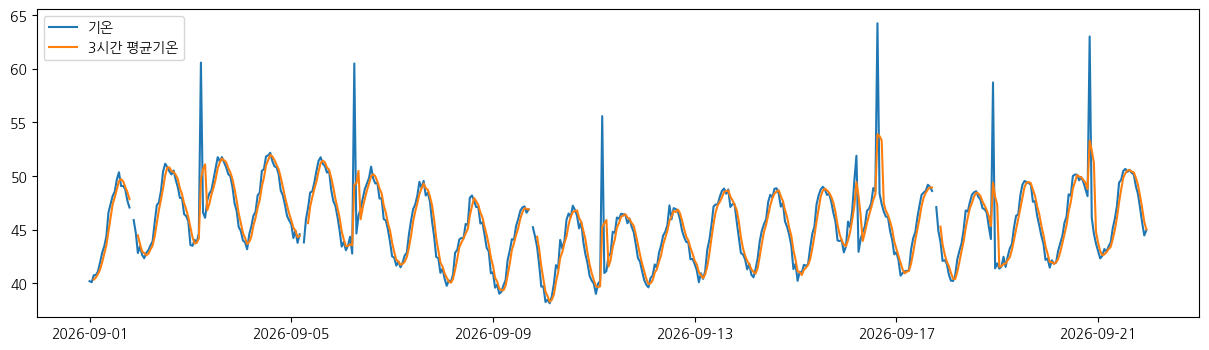

In [ ]:
# plot()

plt.figure(figsize=(15,4))

plt.plot(sensor['측정시각'], sensor['온도_C'], label='기온')
plt.plot(sensor['측정시각'], sensor['이동평균_C'], label='3시간 평균기온')

plt.legend() # 범례
plt.show()

In [ ]:
# 온도_C 가 55도 이상인 값
sensor[sensor['온도_C'] > 55]

,측정시각,설비ID,온도_C,진동_mm_s,전류_A,부하율_pct,이동평균_C
53,2026-09-03 05:00:00,MOTOR-001,60.56,4.977,20.77,59.24,49.670000
126,2026-09-06 06:00:00,MOTOR-001,60.48,4.691,20.87,58.84,49.196667
244,2026-09-11 04:00:00,MOTOR-001,55.57,4.885,19.63,47.84,45.246667
375,2026-09-16 15:00:00,MOTOR-001,64.22,5.293,23.50,71.99,53.883333
430,2026-09-18 22:00:00,MOTOR-001,58.71,4.614,16.99,32.72,49.373333
476,2026-09-20 20:00:00,MOTOR-001,62.99,4.730,19.38,46.13,53.296667


#### 실습 3-1

In [ ]:
# 1) 기본값 : '규칙결과' 걸럼을 생성하여 모든 행을 '기준미초과'로 대체
sensor['규칙결과'] = '기준미초과'

# 2) 결측치는 '확인불가'
sensor.loc[sensor[['온도_C', '진동_mm_s']].isna().any(axis=1), '규칙결과'] = '확인불가'

# 3) 규칙: '온도_C'>=60, '진동_mm_s'>=4.5 인 경우 '확인후보' // rule_flag
rule_flag = (sensor['온도_C'] >= 60) | (sensor['진동_mm_s'] >= 4.5)

sensor.loc[rule_flag,'규칙결과'] = '확인후보'

display(sensor['규칙결과'].value_counts())


,count
규칙결과,
기준미초과,491
확인불가,7
확인후보,6


##### 실습 3-2

In [ ]:
# 후보 목록 : rule_result
rule_result = sensor[sensor['규칙결과'] == '확인후보']

display(rule_result[['측정시각', '온도_C', '진동_mm_s']])

,측정시각,온도_C,진동_mm_s
53,2026-09-03 05:00:00,60.56,4.977
126,2026-09-06 06:00:00,60.48,4.691
244,2026-09-11 04:00:00,55.57,4.885
375,2026-09-16 15:00:00,64.22,5.293
430,2026-09-18 22:00:00,58.71,4.614
476,2026-09-20 20:00:00,62.99,4.730


##### 실습 3-3 시각화

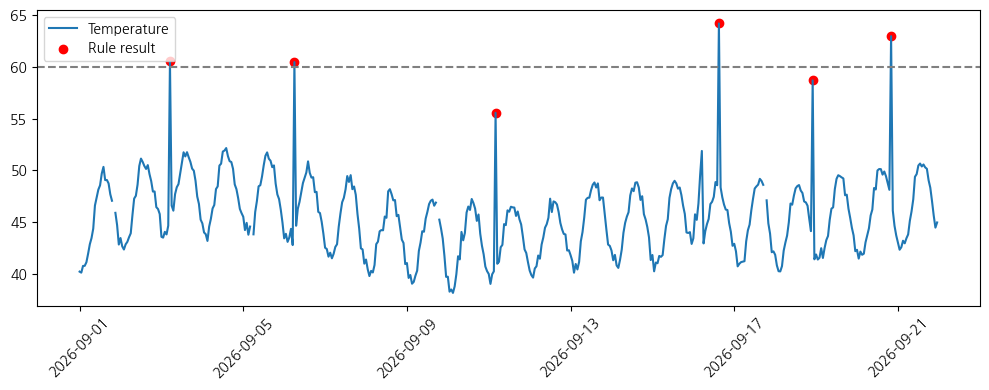

In [ ]:
plt.figure(figsize=(10, 4))

plt.plot(sensor['측정시각'], sensor['온도_C'], label='Temperature')
plt.scatter(rule_result['측정시각'], rule_result['온도_C'], color='red', label='Rule result')

plt.axhline(60, color='gray', linestyle='--')

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

##### 실습 4-1 : 데이터 분할

In [ ]:
# 기간을 나누는 시점 // cutoff
cutoff = pd.Timestamp("2026-09-15")

# AI 에게 입력할 컬럼명 // detect_columns
detect_columns = ['온도_C', '진동_mm_s', '전류_A']

# 학습용(train) : 9/15 이전, 확인용(test) : 9/15 포함 이후
detect_train = sensor[sensor['측정시각'] < cutoff].dropna(subset=detect_columns)
detect_test = sensor[sensor['측정시각'] >= cutoff].dropna(subset=detect_columns)

display(len(detect_train))# 328
display(len(detect_test)) # 165

328

165

##### 실습 4-2 학습과 탐지

In [ ]:
# 모델(IsolationForest)을 만들고 학습, 판정(예측)

# 1) 모델 정의
detecter = IsolationForest(contamination = 0.03, random_state = 42)

# 2) 모델로 학습 : fit() // detect_train
detecter.fit(detect_train[detect_columns])

# 3) 학습된 모델로 판정(예측) : predict() // detect_test
# 결과 : detect_test['AI판정'], detect_test['AI결과']
detect_test['AI판정'] = detecter.predict(detect_test[detect_columns])
detect_test['AI결과'] = detect_test['AI판정'].map({1:'모델미탐지', -1:'확인후보'})

detect_test.AI결과.value_counts()

,count
AI결과,
모델미탐지,153
확인후보,12


In [ ]:
detect_test.head()

,측정시각,설비ID,온도_C,진동_mm_s,전류_A,부하율_pct,이동평균_C,규칙결과,AI판정,AI결과
336,2026-09-15 00:00:00,MOTOR-001,41.81,1.703,11.39,39.83,42.213333,기준미초과,1,모델미탐지
337,2026-09-15 01:00:00,MOTOR-001,40.23,1.826,10.99,39.70,41.120000,기준미초과,1,모델미탐지
338,2026-09-15 02:00:00,MOTOR-001,41.08,1.844,12.47,44.27,41.040000,기준미초과,1,모델미탐지
339,2026-09-15 03:00:00,MOTOR-001,41.01,1.896,11.82,42.79,40.773333,기준미초과,1,모델미탐지
340,2026-09-15 04:00:00,MOTOR-001,41.72,2.002,13.42,51.50,41.270000,기준미초과,1,모델미탐지


##### 실습 5-1

In [ ]:
sensor.head(2)
sensor.columns

Index(['측정시각', '설비ID', '온도_C', '진동_mm_s', '전류_A', '부하율_pct', '이동평균_C', '규칙결과'], dtype='object')

In [ ]:
# 입력과 정답 만들기

# 입력 컬럼명 4개 만들기 // features
features = ['온도_C', '진동_mm_s', '전류_A', '부하율_pct']

# 다음 행의 값을 현재 행에 붙이기 : shift(-1)
sensor['목표시각'] = sensor['측정시각'].shift(-1)
sensor['다음온도_C'] = sensor['온도_C'].shift(-1)

# 필요한 컬럼만 추출 후 결측 행 삭제 // usable
usable = sensor[['측정시각', '온도_C', '진동_mm_s', '전류_A', '부하율_pct', '목표시각', '다음온도_C']]
usable = usable.dropna().reset_index(drop=True)
usable.info() # (488, 7)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 488 entries, 0 to 487
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   측정시각     488 non-null    datetime64[ns]
 1   온도_C     488 non-null    float64       
 2   진동_mm_s  488 non-null    float64       
 3   전류_A     488 non-null    float64       
 4   부하율_pct  488 non-null    float64       
 5   목표시각     488 non-null    datetime64[ns]
 6   다음온도_C   488 non-null    float64       
dtypes: datetime64[ns](2), float64(5)
memory usage: 26.8 KB


In [ ]:
usable.head()

,측정시각,온도_C,진동_mm_s,전류_A,부하율_pct,목표시각,다음온도_C
0,2026-09-01 00:00:00,40.20,1.596,10.34,33.99,2026-09-01 01:00:00,40.10
1,2026-09-01 01:00:00,40.10,1.502,10.37,35.85,2026-09-01 02:00:00,40.75
2,2026-09-01 02:00:00,40.75,1.547,11.50,40.04,2026-09-01 03:00:00,40.76
3,2026-09-01 03:00:00,40.76,1.757,12.65,46.36,2026-09-01 04:00:00,41.11
4,2026-09-01 04:00:00,41.11,1.792,13.09,52.39,2026-09-01 05:00:00,41.94


##### 실습 5-2 학습과 평가 데이터 분리

In [ ]:
# 학습 : 정답 시각(목표시각)이 기준 이전 // train
train = usable[usable['목표시각'] < cutoff]

# 평가 : 측정 시각이 기준 이후 // test
test = usable[usable['측정시각'] >= cutoff].copy()

print('학습:',len(train), '평가', len(test))
print('학습 정답 마지막:', train['목표시각'].max())
print('평가 시작:', test['측정시각'].min())

학습: 324 평가 163
학습 정답 마지막: 2026-09-14 23:00:00
평가 시작: 2026-09-15 00:00:00


##### 실습 5-3 예측과 오차 비교

In [ ]:
features = ['온도_C', '진동_mm_s', '전류_A', '부하율_pct']

In [ ]:
# 모델 만들기
model = RandomForestRegressor(min_samples_leaf=3, random_state=42)

# 모델 훈련하기
model.fit(train[features], train['다음온도_C'])

# 모델 예측하기
test['AI예측온도_C'] = model.predict(test[features])

# 모델 평가하기
ai_mae = mean_absolute_error(test['다음온도_C'], test['AI예측온도_C'])
ai_mse = mean_squared_error(test['다음온도_C'], test['AI예측온도_C'])
ai_r2 = r2_score(test['다음온도_C'], test['AI예측온도_C'])

print('AI MAE:', round(ai_mae, 3))
print('AI MSE:', round(ai_mse, 3))
print('AI R2:', round(ai_r2, 3))


AI MAE: 0.948
AI MSE: 5.384
AI R2: 0.598


##### 실습 6-1 시각화

In [ ]:
test.head()
test.shape # (163, 8)

(163, 8)

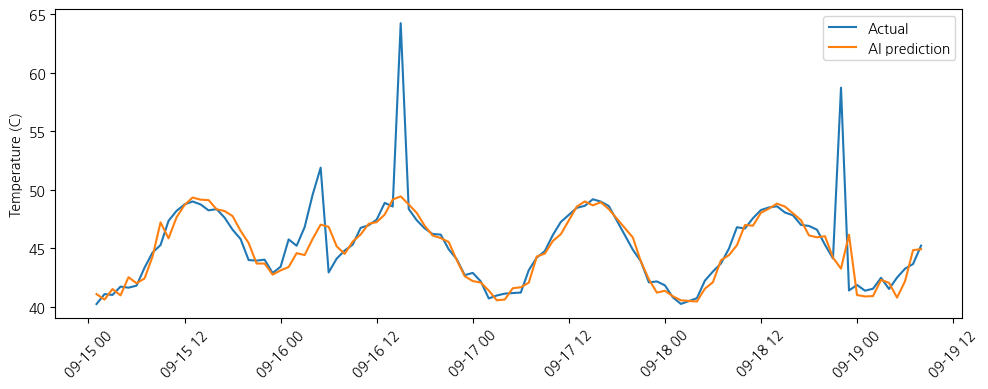

In [ ]:
view = test.head(100)
plt.figure(figsize=(10, 4))

plt.plot(view['목표시각'], view['다음온도_C'], label='Actual')
plt.plot(view['목표시각'], view['AI예측온도_C'], label='AI prediction')
# plt.plot(view['목표시각'], view['기준예측온도_C'], label='Baseline', alpha=0.6)

plt.ylabel('Temperature (C)')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### 실습 6-2

In [ ]:
# AI가 선택한 점검 후보
ai_result = detect_test[detect_test['AI결과'] == '확인후보']

prompt = f"""교육용 가상 모터 MOTOR-001의 분석 결과다.
1. 이상징후 탐지
- 과거 14일의 온도·진동·전류로 Isolation Forest를 학습했다.
- 이후 유효 탐지 기록은 {len(detect_test)}건이다.
- AI가 선택한 점검 후보는 {len(ai_result)}건이다.
- 후보는 실제 고장이 확정된 기록이 아니다.
2. 다음 시간 온도 예측
- 현재 온도·진동·전류·부하율로 다음 1시간 온도를 예측했다.
- 과거 자료로 Random Forest를 학습하고 이후 자료로 평가했다.
- 유효 예측 평가 기록은 {len(test)}건이다.
- 실제 다음 온도와 비교한 MAE는 {ai_mae:.3f}℃이다.
관찰·숫자 근거·한계·추가 확인 사항을 각 1문장으로 작성해 줘.
제공한 숫자만 사용하고 실제 고장이나 원인을 단정하지 마.
MAE만으로 현업 적용 가능성이나 다른 방법보다 우수하다고 단정하지 마.
"""
print(prompt)

교육용 가상 모터 MOTOR-001의 분석 결과다.
1. 이상징후 탐지
- 과거 14일의 온도·진동·전류로 Isolation Forest를 학습했다.
- 이후 유효 탐지 기록은 165건이다.
- AI가 선택한 점검 후보는 12건이다.
- 후보는 실제 고장이 확정된 기록이 아니다.
2. 다음 시간 온도 예측
- 현재 온도·진동·전류·부하율로 다음 1시간 온도를 예측했다.
- 과거 자료로 Random Forest를 학습하고 이후 자료로 평가했다.
- 유효 예측 평가 기록은 163건이다.
- 실제 다음 온도와 비교한 MAE는 0.948℃이다.
관찰·숫자 근거·한계·추가 확인 사항을 각 1문장으로 작성해 줘.
제공한 숫자만 사용하고 실제 고장이나 원인을 단정하지 마.
MAE만으로 현업 적용 가능성이나 다른 방법보다 우수하다고 단정하지 마.



In [ ]:
analysis_result = sensor[sensor["측정시각"] >= cutoff].copy()

analysis_result = analysis_result.merge(
    detect_test[["측정시각", "AI결과"]], on= "측정시각", how="left")
analysis_result["AI결과"]=analysis_result["AI결과"].fillna("입력부족")

analysis_result = analysis_result.merge(
    test[["측정시각", "AI예측온도_C"]], on= "측정시각", how="left")

analysis_result.to_csv("/content/analysis_result.csv", index=False, encoding= "utf-8-sig")
print("저장 완료:", len(analysis_result), "행")

저장 완료: 168 행


In [ ]:
import pandas as pd

# 1) 파일 읽기 // power_raw
power_raw = pd.read_csv("/content/drive/MyDrive/엔지니어링/power_sensor_final.csv")
power_raw.info()

# 2) 결측 개수, 중복 행 수 확인
display(power_raw.isna().sum())
print("완전 중복", power_raw.duplicated().sum())

# 3) 측정시각을 datetime으로 변환
power_raw['측정시각'] = pd.to_datetime(power_raw['측정시각'])

# 4) POWER-002만 추출 // power → 시간순 정렬
power = power_raw[power_raw['설비ID'] == 'POWER-002'].copy()
power = power.sort_values('측정시각').reset_index(drop=True)

# 5) AI 입력 컬럼 // power_columns, 기간 분할 시점 // power_cutoff
power_columns = ['온도_C', '부하율_pct', '전압_V']
power_cutoff = pd.Timestamp("2026-09-15")

print(power.shape)
power.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1512 entries, 0 to 1511
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   측정시각     1512 non-null   object 
 1   설비ID     1512 non-null   object 
 2   온도_C     1512 non-null   float64
 3   부하율_pct  1512 non-null   float64
 4   전압_V     1512 non-null   float64
dtypes: float64(3), object(2)
memory usage: 59.2+ KB


,0
측정시각,0
설비ID,0
온도_C,0
부하율_pct,0
전압_V,0


완전 중복 0
(504, 5)


,측정시각,설비ID,온도_C,부하율_pct,전압_V
0,2026-09-01 00:00:00,POWER-002,51.36,46.39,978.58
1,2026-09-01 01:00:00,POWER-002,50.81,39.87,981.20
2,2026-09-01 02:00:00,POWER-002,50.63,43.12,982.34
3,2026-09-01 03:00:00,POWER-002,49.95,44.42,982.25
4,2026-09-01 04:00:00,POWER-002,50.76,42.70,984.34


In [ ]:
from sklearn.ensemble import IsolationForest

# 1) 기간 분할: 9/15 이전은 학습 // power_past, 9/15 포함 이후는 확인 // power_check
power_past = power[power['측정시각'] < power_cutoff].dropna(subset=power_columns)
power_check = power[power['측정시각'] >= power_cutoff].dropna(subset=power_columns).copy()

print('학습:', len(power_past), '확인:', len(power_check))

# 2) 모델 정의 및 학습
power_detector = IsolationForest(contamination=0.03, random_state=42)
power_detector.fit(power_past[power_columns])

# 3) 판정 결과 열 추가
power_check['AI판정'] = power_detector.predict(power_check[power_columns])
power_check['AI결과'] = power_check['AI판정'].map({1: '모델미탐지', -1: '확인후보'})

display(power_check['AI결과'].value_counts())

# 4) 확인후보만 추출 // power_candidates
power_candidates = power_check[power_check['AI결과'] == '확인후보']

print('확인후보 건수:', len(power_candidates))
display(power_candidates[['측정시각'] + power_columns])

학습: 336 확인: 168


,count
AI결과,
모델미탐지,159
확인후보,9


확인후보 건수: 9


,측정시각,온도_C,부하율_pct,전압_V
368,2026-09-16 08:00:00,69.60,83.88,929.78
418,2026-09-18 10:00:00,70.81,91.96,928.81
453,2026-09-19 21:00:00,61.80,61.85,966.16
454,2026-09-19 22:00:00,62.78,57.34,964.25
455,2026-09-19 23:00:00,63.80,54.63,957.95
456,2026-09-20 00:00:00,65.03,54.68,957.62
457,2026-09-20 01:00:00,64.86,51.70,949.17
482,2026-09-21 02:00:00,52.07,36.92,986.87
488,2026-09-21 08:00:00,70.51,76.42,931.17


학습: 335 평가: 167
AI MAE: 1.189


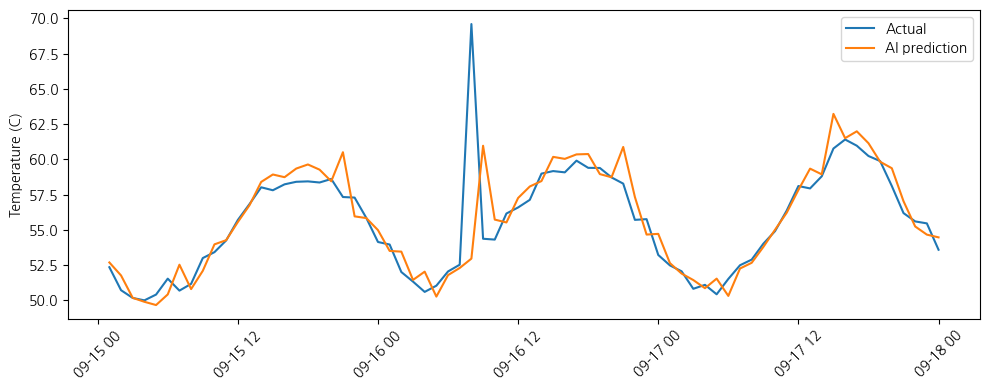

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

# 1) 다음 행의 값을 현재 행에 붙이기 : shift(-1)
power['목표시각'] = power['측정시각'].shift(-1)
power['다음온도_C'] = power['온도_C'].shift(-1)

# 필요한 컬럼만 추출 후 결측 행 삭제 // power_ready
power_ready = power[['측정시각'] + power_columns + ['목표시각', '다음온도_C']]
power_ready = power_ready.dropna().reset_index(drop=True)

# 2) 학습 : 정답 시각이 기준 이전 // power_train,  평가 : 측정 시각이 기준 이후 // power_test
power_train = power_ready[power_ready['목표시각'] < power_cutoff]
power_test = power_ready[power_ready['측정시각'] >= power_cutoff].copy()

print('학습:', len(power_train), '평가:', len(power_test))

# 3) 모델 학습, 예측, MAE
power_model = RandomForestRegressor(min_samples_leaf=3, random_state=42)
power_model.fit(power_train[power_columns], power_train['다음온도_C'])

power_test['AI예측온도_C'] = power_model.predict(power_test[power_columns])

power_mae = mean_absolute_error(power_test['다음온도_C'], power_test['AI예측온도_C'])
print('AI MAE:', round(power_mae, 3))

# 4) 평가 앞 72행 : 실제 vs 예측
view = power_test.head(72)

plt.figure(figsize=(10, 4))
plt.plot(view['목표시각'], view['다음온도_C'], label='Actual')
plt.plot(view['목표시각'], view['AI예측온도_C'], label='AI prediction')

plt.ylabel('Temperature (C)')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
# 1) 9/15 이후 power 자료 복사 // power_result
power_result = power[power['측정시각'] >= power_cutoff].copy()

# 2) power_check의 AI결과 결합 → 빈칸은 '입력부족'
power_result = power_result.merge(
    power_check[['설비ID', '측정시각', 'AI결과']],
    on=['설비ID', '측정시각'], how='left'
)
power_result['AI결과'] = power_result['AI결과'].fillna('입력부족')

# 3) power_test의 AI예측온도_C 결합 (power_test에 설비ID 추가 후 같은 기준으로)
power_result = power_result.merge(
    power_test.assign(설비ID='POWER-002')[['설비ID', '측정시각', 'AI예측온도_C']],
    on=['설비ID', '측정시각'], how='left'
)

# 4) 저장
power_result.to_csv('power_analysis_result.csv', index=False, encoding='utf-8-sig')

power_result.head()

,측정시각,설비ID,온도_C,부하율_pct,전압_V,목표시각,다음온도_C,AI결과,AI예측온도_C
0,2026-09-15 00:00:00,POWER-002,52.67,49.97,979.92,2026-09-15 01:00:00,52.35,모델미탐지,52.688320
1,2026-09-15 01:00:00,POWER-002,52.35,42.86,981.30,2026-09-15 02:00:00,50.72,모델미탐지,51.766284
2,2026-09-15 02:00:00,POWER-002,50.72,45.90,980.96,2026-09-15 03:00:00,50.17,모델미탐지,50.177684
3,2026-09-15 03:00:00,POWER-002,50.17,42.72,980.19,2026-09-15 04:00:00,50.00,모델미탐지,49.897521
4,2026-09-15 04:00:00,POWER-002,50.00,43.44,984.30,2026-09-15 05:00:00,50.41,모델미탐지,49.666835


In [ ]:
!pip install streamlit

In [14]:
%%writefile app_02.py

import pandas as pd
import streamlit as st

# 데이터 읽기
df = pd.read_csv("/content/analysis_result.csv")
df["측정시각"] = pd.to_datetime(df["측정시각"])

# 제목과 설명
st.title("철도 데이터 분석 대시보드")
st.write("교육용 가상 자료입니다. AI 확인후보는 고장 확정이 아닙니다.")

# 데이터 표
st.write("전체 행 수:", len(df))
st.dataframe(df.head(10))

Writing app_02.py


In [15]:
# 방법1) 새창에서 대시보드 표시
APP = "app_02.py"   # 3교시: app_03.py → 4교시: app_04.py → 5교시: app_05.py → 6교시: app.py

# 1) 실행 중인 앱 종료 → 2) 새 앱 실행 → 3) 8초 기다리기
!pkill -f "streamlit run"
!nohup streamlit run {APP} --server.port=8501 --server.headless=true --server.enableCORS=false --server.enableXsrfProtection=false > streamlit.log 2>&1 &
!sleep 8

# 4) 대시보드 주소 출력
from google.colab import output
print("대시보드 주소:", output.eval_js("google.colab.kernel.proxyPort(8501)"))

대시보드 주소: https://8501-m-s-kkb-euw4b2-1pg9x2be4iu27-b.europe-west4-2.prod.colab.dev


In [16]:
APP = "app_02.py"

# 기존 앱 종료
!pkill -f "streamlit run"

# 새 앱 실행
!nohup streamlit run {APP} --server.port=8501 --server.headless=true --server.enableCORS=false --server.enableXsrfProtection=false > streamlit.log 2>&1 &

# 실행 대기
!sleep 8

# 코랩 셀 아래에 대시보드 표시
from google.colab import output
output.serve_kernel_port_as_iframe(8501, height=800)

<IPython.core.display.Javascript object>

In [23]:
%%writefile app_03.py
import pandas as pd
import streamlit as st

# 데이터 읽기
df = pd.read_csv("analysis_result.csv")
df["측정시각"] = pd.to_datetime(df["측정시각"])

# 제목과 설명
st.title("철도 데이터 분석 대시보드")
st.write("교육용 가상 자료입니다. AI 확인후보는 고장 확정이 아닙니다.")

# ★ 설비 선택
equipment = st.selectbox("설비 선택", df["설비ID"].unique())
view = df[df["설비ID"] == equipment]

# ★ 기간 선택 (처음 값: 자료의 첫날 ~ 마지막 날)
start = st.date_input("시작일", view["측정시각"].min().date())
end = st.date_input("종료일", view["측정시각"].max().date())

# ★ 시작일과 종료일을 모두 포함해 조회
view = view[(view["측정시각"].dt.date >= start) & (view["측정시각"].dt.date <= end)]

# ★ 조회 결과
st.write("조회 행 수:", len(view))
if len(view) == 0:
    st.warning("조회 결과가 없습니다. 날짜를 다시 선택하세요.")
st.dataframe(view)


Writing app_03.py


In [24]:
# 방법1) 새창에서 대시보드 표시
APP = "app_03.py"   # 3교시: app_03.py → 4교시: app_04.py → 5교시: app_05.py → 6교시: app.py

# 1) 실행 중인 앱 종료 → 2) 새 앱 실행 → 3) 8초 기다리기
!pkill -f "streamlit run"
!nohup streamlit run {APP} --server.port=8501 --server.headless=true --server.enableCORS=false --server.enableXsrfProtection=false > streamlit.log 2>&1 &
!sleep 8

# 4) 대시보드 주소 출력
from google.colab import output
print("대시보드 주소:", output.eval_js("google.colab.kernel.proxyPort(8501)"))

대시보드 주소: https://8501-m-s-kkb-euw4b2-1pg9x2be4iu27-b.europe-west4-2.prod.colab.dev


In [32]:
%%writefile app_05.py
import pandas as pd
import streamlit as st
import plotly.express as px

# 데이터 읽기
df = pd.read_csv("analysis_result.csv")
df["측정시각"] = pd.to_datetime(df["측정시각"])

# 제목과 설명
st.title("철도 데이터 분석 대시보드")
st.write("교육용 가상 자료입니다. AI 확인후보는 고장 확정이 아닙니다.")

# ★ 설비 선택
equipment = st.selectbox("설비 선택", df["설비ID"].unique())
view = df[df["설비ID"] == equipment]

# ★ 기간 선택 (처음 값: 자료의 첫날 ~ 마지막 날)
start = st.date_input("시작일", view["측정시각"].min().date())
end = st.date_input("종료일", view["측정시각"].max().date())

# ★ 시작일과 종료일을 모두 포함해 조회
view = view[(view["측정시각"].dt.date >= start) & (view["측정시각"].dt.date <= end)]

# ★ 조회 결과
st.write("조회 행 수:", len(view))
if len(view) == 0:
    st.warning("조회 결과가 없습니다. 날짜를 다시 선택하세요.")
st.dataframe(view)

# ★ AI 점검 후보
st.subheader("AI 점검 후보")
candidates = view[view["AI결과"] == "확인후보"]
st.metric("AI 확인후보 건수", len(candidates))
st.dataframe(view["AI결과"].value_counts())

fig = px.line(view, x="측정시각", y="온도_C", title="온도 추이와 AI 확인후보")
fig.add_scatter(x=candidates["측정시각"], y=candidates["온도_C"],
                mode="markers", name="확인후보", marker=dict(color="red", size=10))
st.plotly_chart(fig)
st.dataframe(candidates)

# ★ 다음 1시간 온도 예측
st.subheader("다음 1시간 온도 예측")
pred = view.dropna(subset=["다음온도_C", "AI예측온도_C"])   # 실제·예측이 모두 있는 행
mae = (pred["다음온도_C"] - pred["AI예측온도_C"]).abs().mean()
st.metric("평균 절대 오차(MAE)", f"{mae:.2f} ℃")
st.write("비교한 자료:", len(pred), "건")

fig2 = px.line(pred, x="목표시각", y=["다음온도_C", "AI예측온도_C"], title="실제 온도와 AI 예측 온도")
st.plotly_chart(fig2)

# ★ 업무 메모와 보고서
st.subheader("업무 검토 및 저장")
note = st.text_area("확인할 사항 및 조치 제안", "센서 상태와 운전 조건을 확인한 후 담당자 검토가 필요합니다.")

report = f"""설비: {equipment}
조회 기간: {start} ~ {end}
조회 건수: {len(view)}건
AI 확인후보: {len(candidates)}건
온도 예측 MAE: {mae:.2f} ℃ ({len(pred)}건 비교)
업무 메모: {note}
교육용 가상 자료이며, 확인후보는 고장 확정이 아닙니다."""
st.text(report)

# ★ 파일 내려받기 (현재 조회 결과만)
st.download_button("조회 결과 CSV", view.to_csv(index=False).encode("utf-8-sig"), "dashboard_result.csv")
st.download_button("점검 후보 CSV", candidates.to_csv(index=False).encode("utf-8-sig"), "inspection_candidates.csv")
st.download_button("보고서 TXT", report.encode("utf-8-sig"), "dashboard_report.txt")

Writing app_05.py


In [34]:
# 방법1) 새창에서 대시보드 표시
APP = "app_05.py"   # 3교시: app_03.py → 4교시: app_04.py → 5교시: app_05.py → 6교시: app.py

# 1) 실행 중인 앱 종료 → 2) 새 앱 실행 → 3) 8초 기다리기
!pkill -f "streamlit run"
!nohup streamlit run {APP} --server.port=8501 --server.headless=true --server.enableCORS=false --server.enableXsrfProtection=false > streamlit.log 2>&1 &
!sleep 8

# 4) 대시보드 주소 출력
from google.colab import output
print("대시보드 주소:", output.eval_js("google.colab.kernel.proxyPort(8501)"))

대시보드 주소: https://8501-m-s-kkb-euw4b2-1pg9x2be4iu27-b.europe-west4-2.prod.colab.dev
